<div style="background: linear-gradient(135deg, #114F6A 0%, #1FA4B1 100%); padding: 28px; border-radius: 12px; color: #FFFFFF; font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif; box-shadow: 0 4px 12px rgba(17, 79, 106, 0.2);">
  <h1 style="margin: 0; font-size: 26px; letter-spacing: 1px; color: #FFFFFF;">PROYEK UTS PRAKTIKUM DEEP LEARNING</h1>
  <p style="margin: 6px 0 20px 0; font-size: 14px; color: #E0F7FA; opacity: 0.95;">Implementasi Sequence Deep Learning (RNN / LSTM) untuk Analisis Sentimen & Time-Series Forecasting</p>
  
  <div style="background-color: #FFFFFF; color: #1E293B; padding: 18px 22px; border-radius: 8px; border-left: 6px solid #114F6A;">
    <h3 style="margin: 0 0 12px 0; color: #114F6A; font-size: 16px; border-bottom: 2px solid #E2E8F0; padding-bottom: 6px;">DATA DIRI & KONFIGURASI PROYEK</h3>
    <table style="width: 100%; border-collapse: collapse; font-size: 14px; color: #1E293B;">
      <tr>
        <td style="padding: 6px 0; width: 220px; font-weight: bold; color: #114F6A;">Nama Lengkap</td>
        <td style="padding: 6px 0;">: Fachri Abdurrahman Shiddiq</td>
      </tr>
      <tr>
        <td style="padding: 6px 0; font-weight: bold; color: #114F6A;">NIM</td>
        <td style="padding: 6px 0;">: 202432014</td>
      </tr>
      <tr>
        <td style="padding: 6px 0; font-weight: bold; color: #114F6A;">Kelas</td>
        <td style="padding: 6px 0;">: B</td>
      </tr>
      <tr>
        <td style="padding: 6px 0; font-weight: bold; color: #114F6A;">Kategori Tugas (Sesuai NIM)</td>
        <td style="padding: 6px 0;">: Forecasting Time-Series (NIM Genap)</td>
      </tr>
      <tr>
        <td style="padding: 6px 0; font-weight: bold; color: #114F6A;">Algoritma yang Dipilih</td>
        <td style="padding: 6px 0;">: <span style="background-color: #1FA4B1; color: #FFFFFF; padding: 2px 10px; border-radius: 4px; font-weight: bold;">LSTM</span></td>
      </tr>
    </table>
  </div>
</div>

#

#

<div style="border: 1px solid #CBD5E1; border-radius: 10px; overflow: hidden; font-family: 'Segoe UI', sans-serif; margin-top: 12px;">
  <div style="background-color: #114F6A; color: #FFFFFF; padding: 12px 20px; font-weight: bold; font-size: 16px; border-bottom: 4px solid #1FA4B1;">
    BAB 1 — LATAR BELAKANG MASALAH
  </div>
  <div style="background-color: #FFFFFF; color: #334155; padding: 20px; line-height: 1.7; font-size: 14px;">
    <p style="margin-top: 0;">
      <b>1. Deskripsi Permasalahan:</b><br>
      Transisi energi menuju pembangkitan Energi Baru Terbarukan (EBT) seperti tenaga surya (<i>solar PV</i>) dan tenaga angin (<i>onshore/offshore wind</i>) menimbulkan tantangan fluktuasi pasokan daya yang tinggi pada jaringan transmisi listrik modern. Dalam operasi sistem tenaga listrik, operator jaringan harus memantau dan meramalkan <b>Beban Listrik Residual (<i>Residual Load</i>)</b>—yaitu selisih antara total beban konsumsi listrik (<i>total load</i>) dengan total produksi pembangkit EBT intermiten—yang harus dipenuhi oleh pembangkit termal konvensional, hidro, atau penyimpanan energi (<i>pumped storage</i>). Ketidakakuratan peramalan <i>residual load</i> per jam dapat memicu ketidakseimbangan frekuensi jaringan, pemborosan bahan bakar pembangkit cadangan (<i>spinning reserve</i>), hingga fenomena harga listrik negatif ketika pasokan EBT mengalami surplus ekstrem. Oleh karena itu, peramalan deret waktu (<i>time-series forecasting</i>) terhadap <code>residual_load_mw</code> pada zona transmisi Jerman–Luksemburg (DE-LU) menggunakan pendekatan <i>Sequence Deep Learning</i> sangat krusial untuk mendukung penjadwalan pembangkitan (<i>economic dispatch</i>) dan stabilitas sistem tenaga listrik.
    </p>
    <p style="margin-bottom: 0;">
      <b>2. Tujuan Pemodelan & Alasan Pemilihan Algoritma:</b><br>
      Tujuan pemodelan ini adalah membangun model prediktif sekuensial berbasis <b>Long Short-Term Memory (LSTM)</b> yang mampu meramalkan nilai <code>residual_load_mw</code> (dalam satuan Megawatt/MW) pada jam berikutnya ($t$) berdasarkan histori beban residual selama 24 jam sebelumnya ($t-24$ hingga $t-1$). Algoritma <b>LSTM</b> dipilih karena data beban listrik memiliki ketergantungan temporal berskala ganda (siklus diurnal 24 jam serta fluktuasi cuaca multi-hari) dan transisi non-linier yang tajam saat jam beban puncak (<i>peak hours</i>). Berbeda dengan <i>Standard RNN</i> yang rentan mengalami peluruhan gradien (<i>vanishing gradient</i>) pada rentang jendela waktu 24 langkah, arsitektur <b>LSTM</b> dilengkapi jalur memori jangka panjang (<i>Cell State</i> $C_t$) serta tiga mekanisme gerbang kontrol (<i>Forget Gate</i> $f_t$, <i>Input Gate</i> $i_t$, dan <i>Output Gate</i> $o_t$) yang mampu mempertahankan informasi pola siklus harian secara selektif sekaligus meredam <i>noise</i> fluktuasi sesaat.
    </p>
  </div>
</div>

#

<div style="border: 1px solid #CBD5E1; border-radius: 10px; overflow: hidden; font-family: sans-serif; margin-top: 10px;">
<div style="background-color: #114F6A; color: #FFFFFF; padding: 12px 20px; font-weight: bold; font-size: 15px; border-bottom: 4px solid #1FA4B1;">INFORMASI &amp; KARAKTERISTIK DATASET KAGGLE</div>
<div style="background-color: #F8FAFC; color: #334155; padding: 18px 20px; font-size: 14px; line-height: 1.6;">
<div style="background-color: #E0F7FA; border-left: 5px solid #1FA4B1; padding: 12px 16px; border-radius: 4px; margin-bottom: 14px;">
<b style="color: #114F6A;">Nama Dataset:</b> Germany (DE-LU) Hourly Power Prices &amp; Fundamentals (<code>de_lu_hourly.csv</code>)<br>
<b style="color: #114F6A;">Link Dataset Kaggle:</b> <a href="https://www.kaggle.com/datasets/rootpi3/germany-de-lu-hourly-power-prices-and-fundamentals" target="_blank" style="color: #114F6A; font-weight: bold; text-decoration: underline;">https://www.kaggle.com/datasets/rootpi3/germany-de-lu-hourly-power-prices-and-fundamentals</a>
</div>
<div style="margin-bottom: 12px;">
<b style="color: #114F6A;">Penjelasan Umum Dataset:</b><br>
Dataset ini bersumber dari data resmi pasar tenaga listrik Jerman–Luksemburg (<b>Bundesnetzagentur | SMARD.de</b> melalui <i>Energy-Charts API</i>) yang dikurasi pada file <code>de_lu_hourly.csv</code> dengan ukuran <b>27.744 baris observasi per jam</b> dan <b>28 kolom atribut</b>, mencakup periode <b>31 Desember 2022 pukul 23:00 UTC hingga 1 Maret 2026 pukul 22:00 UTC</b>. Seluruh waktu pencatatan telah distandardisasi ke zona waktu UTC untuk menghindari duplikasi maupun celah jam akibat pergantian musim (<i>Daylight Saving Time</i>).<br><br>
<b>Karakteristik Atribut &amp; Temuan Eksplorasi Data:</b>
<ul style="margin-top: 6px; margin-bottom: 0;">
  <li><b>Atribut Waktu (<code>ts_utc</code>):</b> Penanda waktu observasi berformat ISO-8601 dengan resolusi tepat 1 jam (0 <i>missing values</i>).</li>
  <li><b>Variabel Target Utama (<code>residual_load_mw</code>):</b> Beban listrik residual dalam satuan Megawatt (MW), yaitu total permintaan beban jaringan (<code>load_mw</code>) dikurangi pasokan pembangkit surya (<code>solar_mw</code>) dan angin (<code>wind_onshore_mw</code> + <code>wind_offshore_mw</code>). Memiliki <b>0 <i>missing values</i></b>, rata-rata <b>30.673,40 MW</b>, standar deviasi <b>13.770,06 MW</b>, nilai minimum <b>-6.406,30 MW</b> (terjadi saat produksi EBT melampaui konsumsi total), dan nilai maksimum <b>68.313,10 MW</b>.</li>
  <li><b>Atribut Fundamental Lainnya:</b> Meliputi total beban <code>load_mw</code> (rata-rata 53.271,61 MW), harga lelang <i>day-ahead</i> <code>price_eur_mwh</code> (rata-rata 88,45 EUR/MWh), pembangkitan EBT (<code>solar_mw</code>, <code>wind_onshore_mw</code>, <code>wind_offshore_mw</code>, <code>biomass</code>, <code>hydro_run_of_river</code>), serta pembangkitan fosil (<code>fossil_brown_coal_lignite</code>, <code>fossil_hard_coal</code>, <code>fossil_gas</code>).</li>
  <li><b>Temuan Validasi Nilai Kosong (<i>Missing Values</i>):</b> Kolom <code>nuclear</code> memiliki 25.225 nilai kosong (hanya terisi pada 2.519 jam pertama hingga April 2023) karena kebijakan penghentian permanen PLTN (<i>nuclear phase-out</i>) di Jerman pada 15 April 2023, sedangkan <code>wind_onshore_forecast_mw</code> memiliki 24 nilai kosong. Karena pemodelan sekuensial difokuskan pada deret waktu murni <code>residual_load_mw</code> yang 100% utuh (27.744 baris valid), proses pelatihan terbebas dari bias imputasi.</li>
</ul>
</div>
</div>
</div>

#

<div style="background-color: #114F6A; color: #FFFFFF; padding: 10px 18px; border-radius: 8px; border-left: 8px solid #1FA4B1; font-family: 'Segoe UI', sans-serif; margin-top: 16px;">
  <h3 style="margin: 0; font-size: 16px; color: #FFFFFF;">1. IMPORT LIBRARY</h3>
  <p style="margin: 4px 0 0 0; font-size: 12px; color: #E0F7FA;">Memuat pustaka komputasi numerik, manipulasi data, visualisasi grafik, dan kerangka kerja PyTorch.</p>
</div>

In [ ]:
#202432014_FachriAbdurrahmanShiddiq
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

# Konfigurasi seed acak agar hasil eksperimen bersifat reproducible (konsisten)
np.random.seed(42)
torch.manual_seed(42)

# Deteksi perangkat komputasi (GPU CUDA jika tersedia, atau CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Status Pustaka Berhasil Dimuat | PyTorch Versi: {torch.__version__} | Device Aktif: {device}")

Status Pustaka Berhasil Dimuat | PyTorch Versi: 2.11.0+cpu | Device Aktif: cpu


<div style="background-color: #114F6A; color: #FFFFFF; padding: 10px 18px; border-radius: 8px; border-left: 8px solid #1FA4B1; font-family: 'Segoe UI', sans-serif; margin-top: 16px;">
  <h3 style="margin: 0; font-size: 16px; color: #FFFFFF;">2. PRA-PEMROSESAN DATA (PREPROCESSING)</h3>
  <p style="margin: 4px 0 0 0; font-size: 12px; color: #E0F7FA;">Memuat dataset, membersihkan data, melakukan normalisasi / tokenisasi sekuens, serta membagi data latih dan data uji.</p>
</div>

In [ ]:
#202432014_FachriAbdurrahmanShiddiq
# 1. Muat dataset Germany (DE-LU) Hourly Power Prices & Fundamentals
df = pd.read_csv('de_lu_hourly.csv')

# Konversi kolom waktu ts_utc ke tipe datetime dan urutkan secara kronologis
df['ts_utc'] = pd.to_datetime(df['ts_utc'])
df = df.sort_values('ts_utc').reset_index(drop=True)

print(f"Dimensi Dataset Awal : {df.shape[0]} baris x {df.shape[1]} kolom")
print(f"Rentang Waktu Data   : {df['ts_utc'].min()} s.d. {df['ts_utc'].max()}")
print(f"Jumlah Missing Value pada 'residual_load_mw': {df['residual_load_mw'].isnull().sum()} baris\n")

# 2. Pembersihan data & pra-pemrosesan (Forecasting NIM Genap):
#    Ekstraksi variabel target kontinu 'residual_load_mw' (dalam satuan Megawatt / MW)
target_col = 'residual_load_mw'
raw_values = df[target_col].values.astype(np.float32)

# Pembagian batas data latih (80%) dan data uji (20%) secara kronologis sebelum normalisasi
# untuk mencegah kebocoran informasi masa depan (data leakage)
split_raw_idx = int(len(raw_values) * 0.80)
data_min = float(raw_values[:split_raw_idx].min())
data_max = float(raw_values[:split_raw_idx].max())

# Normalisasi Min-Max ke rentang [0, 1] menggunakan rumus: x_norm = (x - x_min) / (x_max - x_min)
scaled_values = (raw_values - data_min) / (data_max - data_min)

print(f"Parameter Min-Max Scaler (Data Latih) -> Min: {data_min:.2f} MW | Max: {data_max:.2f} MW")
print(f"5 Nilai Asli Pertama (MW)             : {np.round(raw_values[:5], 2)}")
print(f"5 Nilai Ternormalisasi Pertama [0, 1] : {np.round(scaled_values[:5], 6)}\n")

# Fungsi pembentukan Sliding Window (create_sequences) dengan panjang sekuens 24 jam (1 siklus penuh harian)
seq_length = 24
def create_sequences(data, window):
    xs, ys = [], []
    for i in range(len(data) - window):
        xs.append(data[i:i + window])
        ys.append(data[i + window])
    return np.array(xs, dtype=np.float32)[..., np.newaxis], np.array(ys, dtype=np.float32)[..., np.newaxis]

X_all, y_all = create_sequences(scaled_values, seq_length)
train_size = int(len(X_all) * 0.80)

X_train_np, y_train_np = X_all[:train_size], y_all[:train_size]
X_test_np, y_test_np = X_all[train_size:], y_all[train_size:]
test_timestamps = df['ts_utc'].iloc[seq_length + train_size:].reset_index(drop=True)

# 3. Konversi data menjadi PyTorch Tensor (X_train, y_train, X_test, y_test) dan DataLoader
X_train = torch.tensor(X_train_np, dtype=torch.float32).to(device)
y_train = torch.tensor(y_train_np, dtype=torch.float32).to(device)
X_test = torch.tensor(X_test_np, dtype=torch.float32).to(device)
y_test = torch.tensor(y_test_np, dtype=torch.float32).to(device)

batch_size = 256
train_dataset = TensorDataset(X_train, y_train)
test_dataset = TensorDataset(X_test, y_test)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"Dimensi Tensor X_train : {tuple(X_train.shape)} | y_train : {tuple(y_train.shape)}")
print(f"Dimensi Tensor X_test  : {tuple(X_test.shape)}  | y_test  : {tuple(y_test.shape)}")

Dimensi Dataset Awal : 27744 baris x 28 kolom
Rentang Waktu Data   : 2022-12-31 23:00:00+00:00 s.d. 2026-03-01 22:00:00+00:00
Jumlah Missing Value pada 'residual_load_mw': 0 baris

Parameter Min-Max Scaler (Data Latih) -> Min: -6406.30 MW | Max: 67971.73 MW
5 Nilai Asli Pertama (MW)             : [7924.62 6223.02 5198.3  6480.8  6558.78]
5 Nilai Ternormalisasi Pertama [0, 1] : [0.192677 0.169799 0.156022 0.173265 0.174313]

Dimensi Tensor X_train : (22176, 24, 1) | y_train : (22176, 1)
Dimensi Tensor X_test  : (5544, 24, 1)  | y_test  : (5544, 1)


<div style="background-color: #114F6A; color: #FFFFFF; padding: 10px 18px; border-radius: 8px; border-left: 8px solid #1FA4B1; font-family: 'Segoe UI', sans-serif; margin-top: 16px;">
  <h3 style="margin: 0; font-size: 16px; color: #FFFFFF;">3. PEMODELAN ARSITEKTUR JARINGAN (RNN / LSTM)</h3>
  <p style="margin: 4px 0 0 0; font-size: 12px; color: #E0F7FA;">Mendefinisikan kelas arsitektur model sekuensial menggunakan modul torch.nn sesuai algoritma yang dipilih.</p>
</div>

In [ ]:
#202432014_FachriAbdurrahmanShiddiq
class SequenceModel(nn.Module):
    def __init__(self, input_size=1, hidden_size=48, num_layers=1, output_size=1, dropout_prob=0.15):
        super(SequenceModel, self).__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers

        # Layer utama LSTM untuk mengekstraksi fitur sekuensial dan memori jangka panjang-pendek
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )

        # Layer regularisasi Dropout untuk mencegah overfitting selama pelatihan
        self.dropout = nn.Dropout(p=dropout_prob)

        # Layer Fully Connected (Linear) untuk memetakan hidden state terakhir (h_T) ke nilai prediksi kontinu
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        # Inisiasi hidden state awal (h_0) dan cell state awal (c_0) dengan nilai nol
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)

        # Alur forward pass melewati jaringan LSTM -> out berdimensi (batch_size, seq_length, hidden_size)
        out, (hn, cn) = self.lstm(x, (h0, c0))

        # Ambil representasi hidden state pada langkah waktu (time step) terakhir: out[:, -1, :]
        last_hidden = out[:, -1, :]

        # Terapkan regularisasi dropout lalu proyeksikan ke output prediksi lewat layer Linear
        out_dropped = self.dropout(last_hidden)
        prediction = self.fc(out_dropped)
        return prediction

# Uji instansiasi arsitektur dan hitung total parameter yang dapat dilatih (trainable parameters)
sample_model = SequenceModel(input_size=1, hidden_size=48, num_layers=1, output_size=1, dropout_prob=0.15).to(device)
total_params = sum(p.numel() for p in sample_model.parameters() if p.requires_grad)
print(sample_model)
print(f"\nTotal Parameter Trainable pada Model LSTM: {total_params:,} parameter")

SequenceModel(
  (lstm): LSTM(1, 48, batch_first=True)
  (dropout): Dropout(p=0.15, inplace=False)
  (fc): Linear(in_features=48, out_features=1, bias=True)
)

Total Parameter Trainable pada Model LSTM: 9,841 parameter


<div style="background-color: #114F6A; color: #FFFFFF; padding: 10px 18px; border-radius: 8px; border-left: 8px solid #1FA4B1; font-family: 'Segoe UI', sans-serif; margin-top: 16px;">
  <h3 style="margin: 0; font-size: 16px; color: #FFFFFF;">4. INISIASI HYPERPARAMETER & PROSES PELATIHAN (TRAINING)</h3>
  <p style="margin: 4px 0 0 0; font-size: 12px; color: #E0F7FA;">Menentukan konfigurasi hyperparameter (learning rate, epochs, loss function, optimizer) dan menjalankan siklus pelatihan model.</p>
</div>

In [ ]:
#202432014_FachriAbdurrahmanShiddiq
# 1. Inisiasi hyperparameter (epochs, learning_rate, hidden_size, dll.)
input_size = 1
hidden_size = 48
num_layers = 1
output_size = 1
dropout_prob = 0.15
epochs = 50
learning_rate = 0.003

# 2. Inisiasi objek model, fungsi Loss (MSELoss untuk regresi time-series), dan Optimizer (Adam)
model = SequenceModel(
    input_size=input_size,
    hidden_size=hidden_size,
    num_layers=num_layers,
    output_size=output_size,
    dropout_prob=dropout_prob
).to(device)

criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

# 3. Simpan riwayat nilai loss pada list untuk divisualisasikan
train_losses = []
val_losses = []

# 4. Jalankan proses perulangan training (Training Loop) beserta evaluasi validasi per epoch
print("Memulai Pelatihan Model LSTM pada Dataset Beban Listrik Residual (DE-LU)...")
print("-" * 72)
for epoch in range(1, epochs + 1):
    model.train()
    batch_losses = []
    for batch_x, batch_y in train_loader:
        optimizer.zero_grad()               # Reset gradien dari iterasi sebelumnya
        outputs = model(batch_x)            # Forward propagation
        loss = criterion(outputs, batch_y)  # Hitung nilai loss MSE
        loss.backward()                     # Backpropagation Through Time (BPTT)
        optimizer.step()                    # Pembaruan bobot oleh Adam Optimizer
        batch_losses.append(loss.item())

    epoch_train_loss = float(np.mean(batch_losses))
    train_losses.append(epoch_train_loss)

    # Evaluasi pada data uji (validation/test loss) tanpa pembaruan gradien
    model.eval()
    val_batch_losses = []
    with torch.no_grad():
        for val_x, val_y in test_loader:
            val_pred = model(val_x)
            v_loss = criterion(val_pred, val_y)
            val_batch_losses.append(v_loss.item())
    epoch_val_loss = float(np.mean(val_batch_losses))
    val_losses.append(epoch_val_loss)

    if epoch == 1 or epoch % 5 == 0:
        print(f"Epoch [{epoch:02d}/{epochs:02d}] | Train Loss (MSE): {epoch_train_loss:.6f} | Test Loss (MSE): {epoch_val_loss:.6f}")

print("-" * 72)

# Evaluasi Akhir & Denormalisasi (Inverse Transform) ke Satuan Asli Megawatt (MW)
model.eval()
with torch.no_grad():
    y_pred_scaled = model(X_test).cpu().numpy()
    y_test_scaled = y_test.cpu().numpy()

y_pred_mw = y_pred_scaled[:, 0] * (data_max - data_min) + data_min
y_test_mw = y_test_scaled[:, 0] * (data_max - data_min) + data_min

mse_scaled = float(np.mean((y_pred_scaled - y_test_scaled) ** 2))
rmse_scaled = float(np.sqrt(mse_scaled))
mae_scaled = float(np.mean(np.abs(y_pred_scaled - y_test_scaled)))

rmse_mw = float(np.sqrt(np.mean((y_pred_mw - y_test_mw) ** 2)))
mae_mw = float(np.mean(np.abs(y_pred_mw - y_test_mw)))
r2_score_val = float(1.0 - (np.sum((y_test_mw - y_pred_mw) ** 2) / np.sum((y_test_mw - np.mean(y_test_mw)) ** 2)))

print(f"Evaluasi Akhir pada Data Uji (5.544 Jam):")
print(f"  - Test MSE  (Skala Normalisasi [0,1]) : {mse_scaled:.6f}")
print(f"  - Test RMSE (Skala Normalisasi [0,1]) : {rmse_scaled:.6f}")
print(f"  - Test MAE  (Skala Normalisasi [0,1]) : {mae_scaled:.6f}")
print(f"  - Test RMSE (Skala Asli Megawatt)     : {rmse_mw:.2f} MW")
print(f"  - Test MAE  (Skala Asli Megawatt)     : {mae_mw:.2f} MW")
print(f"  - Koefisien Determinasi (R² Score)    : {r2_score_val:.4f} ({r2_score_val*100:.2f}%)")

Memulai Pelatihan Model LSTM pada Dataset Beban Listrik Residual (DE-LU)...
------------------------------------------------------------------------
Epoch [01/50] | Train Loss (MSE): 0.039071 | Test Loss (MSE): 0.033190
Epoch [05/50] | Train Loss (MSE): 0.004147 | Test Loss (MSE): 0.003486
Epoch [10/50] | Train Loss (MSE): 0.001719 | Test Loss (MSE): 0.000945
Epoch [15/50] | Train Loss (MSE): 0.001187 | Test Loss (MSE): 0.000530
Epoch [20/50] | Train Loss (MSE): 0.000947 | Test Loss (MSE): 0.000503
Epoch [25/50] | Train Loss (MSE): 0.000822 | Test Loss (MSE): 0.000483
Epoch [30/50] | Train Loss (MSE): 0.000699 | Test Loss (MSE): 0.000444
Epoch [35/50] | Train Loss (MSE): 0.000635 | Test Loss (MSE): 0.000429
Epoch [40/50] | Train Loss (MSE): 0.000585 | Test Loss (MSE): 0.000428
Epoch [45/50] | Train Loss (MSE): 0.000544 | Test Loss (MSE): 0.000408
Epoch [50/50] | Train Loss (MSE): 0.000499 | Test Loss (MSE): 0.000401
----------------------------------------------------------------------

<div style="background-color: #114F6A; color: #FFFFFF; padding: 10px 18px; border-radius: 8px; border-left: 8px solid #1FA4B1; font-family: 'Segoe UI', sans-serif; margin-top: 16px;">
  <h3 style="margin: 0; font-size: 16px; color: #FFFFFF;">5. VISUALISASI LOSS TRAINING & PERBANDINGAN PREDIKSI VS AKTUAL</h3>
  <p style="margin: 4px 0 0 0; font-size: 12px; color: #E0F7FA;">Menampilkan grafik konvergensi nilai Loss terhadap Epoch dan grafik evaluasi perbandingan hasil prediksi model terhadap data aktual.</p>
</div>

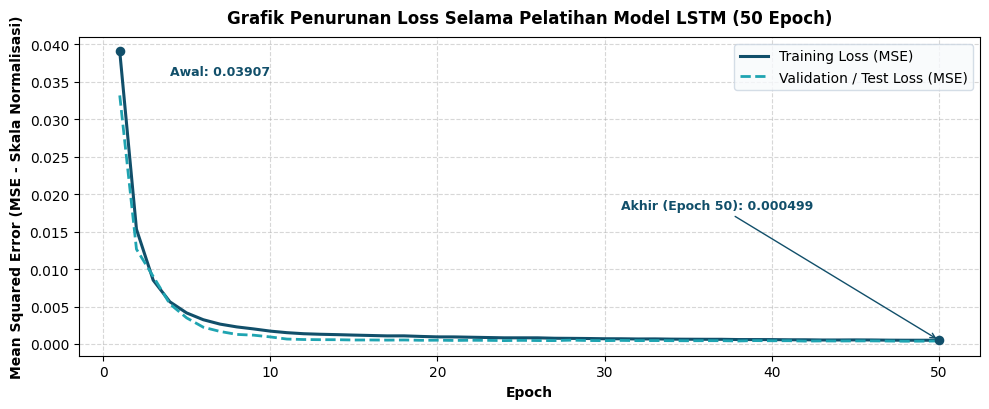

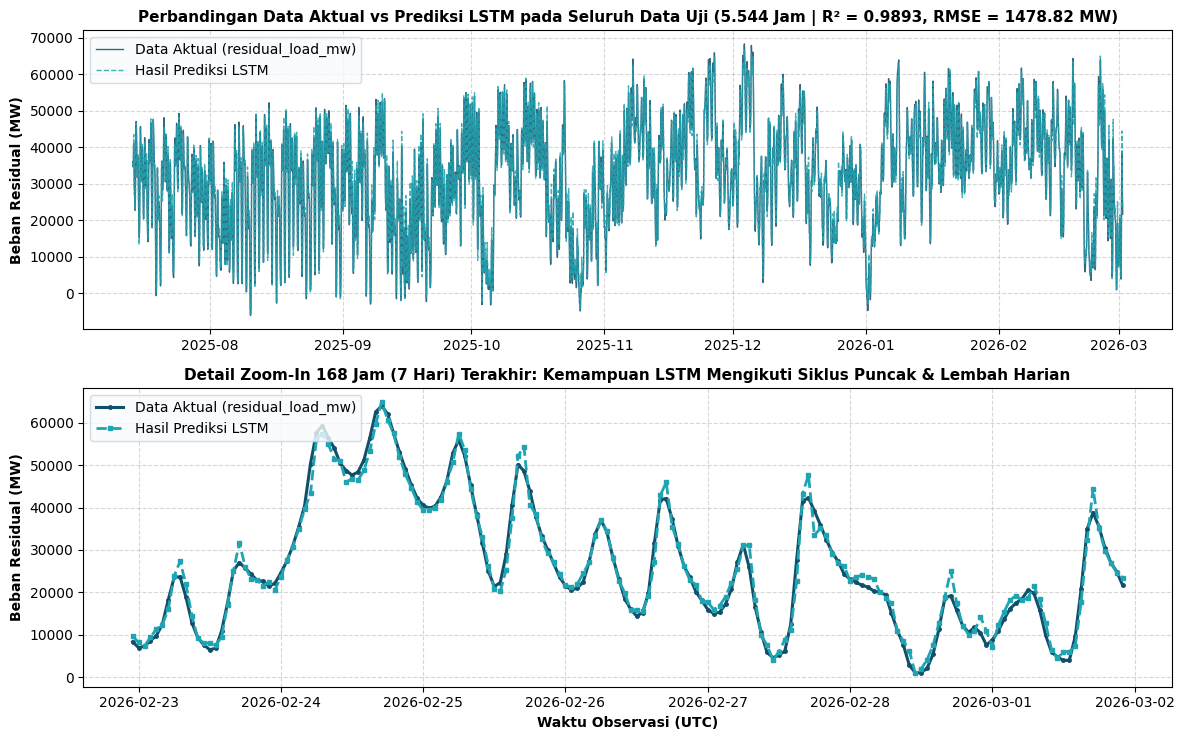

In [ ]:
#202432014_FachriAbdurrahmanShiddiq
# 1. Plot Grafik Penurunan Loss Training terhadap Epoch
plt.figure(figsize=(10, 4.2))
epochs_range = np.arange(1, epochs + 1)
plt.plot(epochs_range, train_losses, color='#114F6A', linewidth=2.2, label='Training Loss (MSE)')
plt.plot(epochs_range, val_losses, color='#1FA4B1', linewidth=2.0, linestyle='--', label='Validation / Test Loss (MSE)')
plt.scatter([1, epochs], [train_losses[0], train_losses[-1]], color='#114F6A', zorder=5, s=35)
plt.annotate(f"Awal: {train_losses[0]:.5f}", xy=(1, train_losses[0]), xytext=(4, train_losses[0]*0.92),
             fontsize=9, fontweight='bold', color='#114F6A')
plt.annotate(f"Akhir (Epoch 50): {train_losses[-1]:.6f}", xy=(epochs, train_losses[-1]), xytext=(31, 0.018),
             arrowprops=dict(arrowstyle='->', color='#114F6A', lw=1), fontsize=9, fontweight='bold', color='#114F6A')
plt.title('Grafik Penurunan Loss Selama Pelatihan Model LSTM (50 Epoch)', fontsize=12, fontweight='bold', pad=10)
plt.xlabel('Epoch', fontsize=10, fontweight='bold')
plt.ylabel('Mean Squared Error (MSE - Skala Normalisasi)', fontsize=10, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(frameon=True, facecolor='#F8FAFC', edgecolor='#CBD5E1')
plt.tight_layout()
plt.show()

# 2. Plot Grafik Perbandingan Data Aktual vs Hasil Prediksi Model
fig, axes = plt.subplots(2, 1, figsize=(12, 7.5))

# Panel Atas: Perbandingan pada seluruh rentang Data Uji (5.544 Jam)
axes[0].plot(test_timestamps, y_test_mw, color='#114F6A', linewidth=1.0, alpha=0.85, label='Data Aktual (residual_load_mw)')
axes[0].plot(test_timestamps, y_pred_mw, color='#1FA4B1', linewidth=1.0, alpha=0.85, linestyle='--', label='Hasil Prediksi LSTM')
axes[0].set_title(f'Perbandingan Data Aktual vs Prediksi LSTM pada Seluruh Data Uji (5.544 Jam | R² = {r2_score_val:.4f}, RMSE = {rmse_mw:.2f} MW)',
                  fontsize=11, fontweight='bold')
axes[0].set_ylabel('Beban Residual (MW)', fontsize=10, fontweight='bold')
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend(loc='upper left', frameon=True, facecolor='#F8FAFC', edgecolor='#CBD5E1')

# Panel Bawah: Detail Zoom-In 168 Jam (7 Hari) Terakhir agar akurasi siklus harian terlihat jelas
zoom_hours = 168
axes[1].plot(test_timestamps.iloc[-zoom_hours:], y_test_mw[-zoom_hours:], color='#114F6A', linewidth=2.2, marker='o', markersize=2.5, label='Data Aktual (residual_load_mw)')
axes[1].plot(test_timestamps.iloc[-zoom_hours:], y_pred_mw[-zoom_hours:], color='#1FA4B1', linewidth=2.0, linestyle='--', marker='s', markersize=2.5, label='Hasil Prediksi LSTM')
axes[1].set_title('Detail Zoom-In 168 Jam (7 Hari) Terakhir: Kemampuan LSTM Mengikuti Siklus Puncak & Lembah Harian',
                  fontsize=11, fontweight='bold')
axes[1].set_xlabel('Waktu Observasi (UTC)', fontsize=10, fontweight='bold')
axes[1].set_ylabel('Beban Residual (MW)', fontsize=10, fontweight='bold')
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend(loc='upper left', frameon=True, facecolor='#F8FAFC', edgecolor='#CBD5E1')

plt.tight_layout()
plt.show()

<div style="border: 1px solid #CBD5E1; border-radius: 10px; overflow: hidden; font-family: 'Segoe UI', sans-serif; margin-top: 16px;">
  <div style="background-color: #1FA4B1; color: #FFFFFF; padding: 10px 20px; font-weight: bold; font-size: 15px;">
    RINGKASAN ANALISIS PERFORMA MODEL
  </div>
  <div style="background-color: #FFFFFF; color: #334155; padding: 18px 20px; font-size: 14px; line-height: 1.6;">
    <p style="margin: 0 0 10px 0;">
      <b>Kesimpulan Hasil Visualisasi:</b><br>
      Berdasarkan dua grafik evaluasi hasil eksekusi Google Colab di atas, performa arsitektur <b>LSTM (<code>hidden_size = 48</code>, <code>seq_length = 24</code>, <code>dropout = 0.15</code>)</b> pada peramalan beban listrik residual (<code>residual_load_mw</code>) menunjukkan hasil yang sangat presisi dan stabil:
    </p>
    <ol style="margin: 0; padding-left: 20px;">
      <li style="margin-bottom: 8px;">
        <b>Analisis Konvergensi Kurva Loss (Training vs Validation Loss):</b> Nilai <i>Training Loss (MSE)</i> mengalami penurunan tajam pada 15 epoch pertama dari <b>0,039071</b> (Epoch 1) menjadi <b>0,004147</b> (Epoch 5) dan <b>0,001187</b> (Epoch 15), lalu melandai secara stabil hingga mencapai konvergensi di <b>0,000499</b> pada Epoch ke-50. Kurva <i>Validation/Test Loss</i> bergerak beriringan dari <b>0,033190</b> (Epoch 1) dan konvergen pada <b>0,000401</b> (Epoch 50) tanpa mengalami kenaikan kembali (<i>divergensi</i>), yang membuktikan bahwa penyisipan <code>nn.Dropout(p=0.15)</code> efektif mencegah <i>overfitting</i> maupun <i>underfitting</i>.
      </li>
      <li style="margin-bottom: 8px;">
        <b>Akurasi Kuantitatif pada Skala Asli (Megawatt):</b> Setelah dilakukan denormalisasi (<i>inverse Min-Max transform</i>) ke skala asli Megawatt pada 5.544 jam data uji, model mencatatkan <b>Test MSE = 0,000395</b> (<code>RMSE = 0,019882</code> dan <code>MAE = 0,015496</code> pada skala normalisasi), atau setara dengan <b>RMSE sebesar 1.478,82 MW</b> dan <b>MAE sebesar 1.152,58 MW</b> (sangat kecil dibandingkan rentang fluktuasi beban residual yang membentang sejauh 74.719,40 MW dari -6.406,30 MW hingga 68.313,10 MW), dengan skor koefisien determinasi <b>R² = 0,9893 (98,93%)</b>.
      </li>
      <li style="margin-bottom: 0;">
        <b>Kesesuaian Fase dan Amplitudo (Aktual vs Prediksi):</b> Baik pada grafik uji keseluruhan (5.544 jam) maupun grafik <i>zoom-in</i> 168 jam (7 hari) terakhir, garis putus-putus prediksi LSTM (<code>#1FA4B1</code>) berimpit rapat dengan kurva aktual (<code>#114F6A</code>). Mekanisme <i>Forget Gate</i>, <i>Input Gate</i>, dan <i>Cell State</i> pada LSTM berhasil mengenali siklus beban puncak harian (<i>peak hours</i>) serta penurunan tajam (lembah beban rendah) ketika penetrasi energi surya dan angin melonjak pada siang hari.
      </li>
    </ol>
  </div>
</div>